In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.6 MB/s eta 0:00:00


Lab 1 ~ 3. Classical Feature Space
   Age  Income  VIP
0   25      45    0
1   32      52    0
2   47      80    1
3   52      90    1


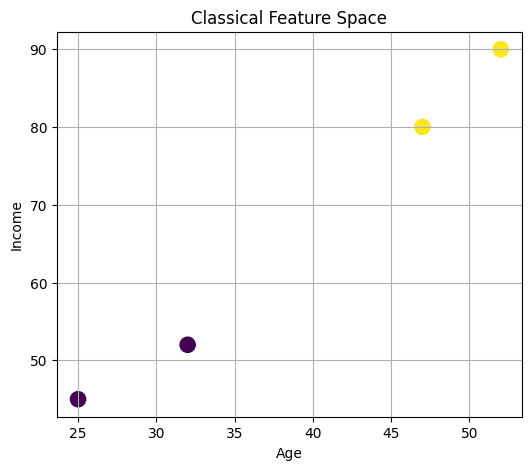


Lab 4 ~ 6. Quantum Circuit & Encoding


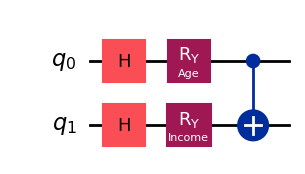


Lab 7 ~ 9. Parameter Binding & ZZ Feature Map


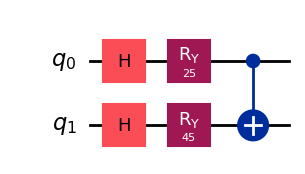

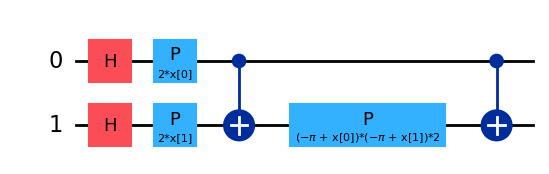

===== My Circuit =====
     ┌───┐┌────────┐     
q_0: ┤ H ├┤ Ry(25) ├──■──
     ├───┤├────────┤┌─┴─┐
q_1: ┤ H ├┤ Ry(45) ├┤ X ├
     └───┘└────────┘└───┘

===== ZZ Feature Map =====
   ┌───┐┌───────────┐                                          
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├
   └───┘└───────────┘└───┘└──────────────────────────────┘└───┘

Lab 10 ~ 12. Quantum State & Visualization (Bloch / QSphere)
Statevector: Statevector([-0.20544443+0.j, -0.6336271 +0.j, -0.72385666+0.j,
             -0.17983555+0.j],
            dims=(2, 2))


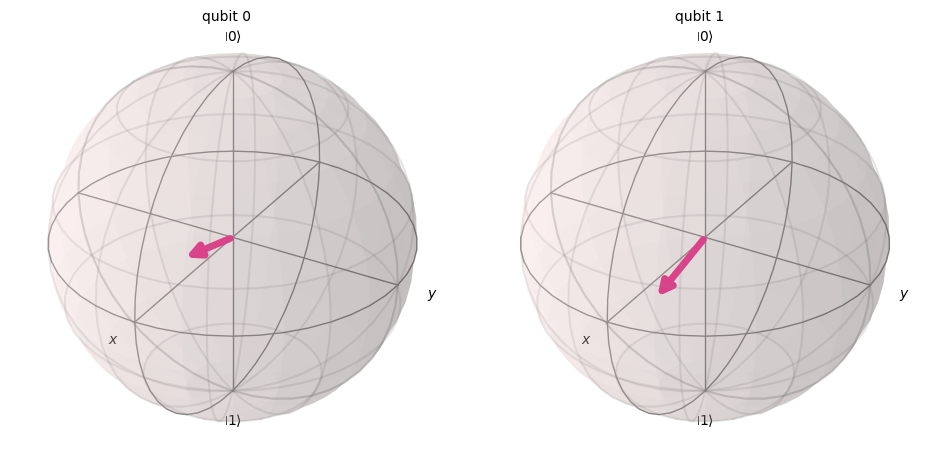

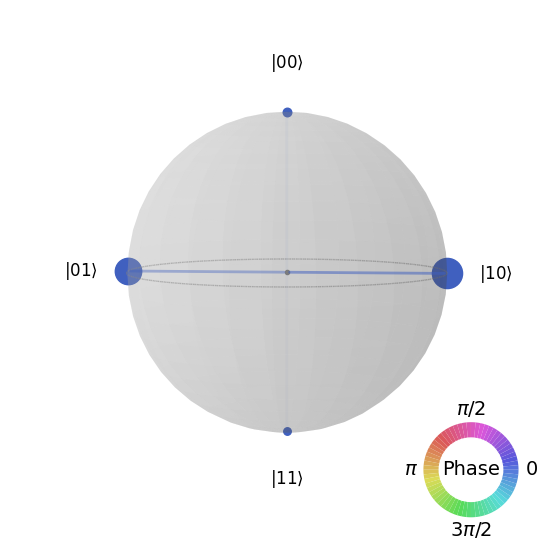


Lab 13 ~ 15. Measurement, Simulation & Histogram


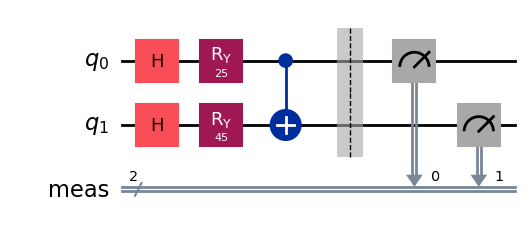

Counts: {'11': 30, '01': 413, '00': 45, '10': 536}


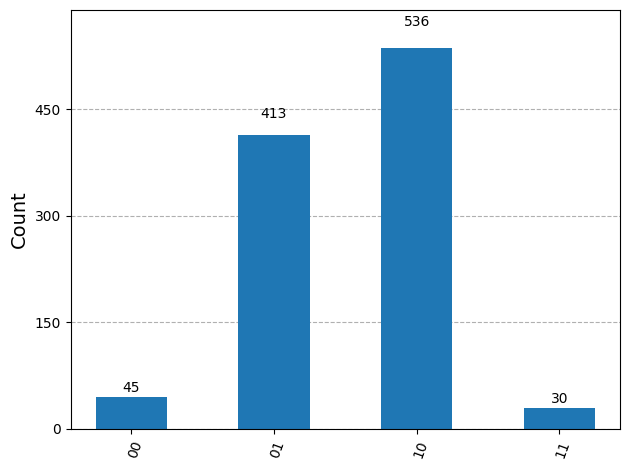


Quantum Feature Space Lab Completed Successfully!


In [26]:
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import zz_feature_map
from qiskit_aer import AerSimulator
from qiskit.visualization import (
    plot_histogram,
    plot_bloch_multivector,
    plot_state_qsphere,
)

###############################################################
# Lab 1 & 2 & 3: 데이터셋 및 산점도
###############################################################
print("=" * 70)
print("Lab 1 ~ 3. Classical Feature Space")
print("=" * 70)

customer = pd.DataFrame(
    {"Age": [25, 32, 47, 52], "Income": [45, 52, 80, 90], "VIP": [0, 0, 1, 1]}
)
print(customer)

plt.figure(figsize=(6, 5))
plt.scatter(customer["Age"], customer["Income"], c=customer["VIP"], s=120)
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Classical Feature Space")
plt.grid(True)
plt.show()

###############################################################
# Lab 4 & 5 & 6: 양자 회로 및 인코딩 설계
###############################################################
print("\n" + "=" * 70)
print("Lab 4 ~ 6. Quantum Circuit & Encoding")
print("=" * 70)

age = Parameter("Age")
income = Parameter("Income")

feature_circuit = QuantumCircuit(2)
feature_circuit.h(0)
feature_circuit.h(1)
feature_circuit.ry(age, 0)
feature_circuit.ry(income, 1)
feature_circuit.cx(0, 1)

display(feature_circuit.draw("mpl"))

###############################################################
# Lab 7 & 8 & 9: 파라미터 바인딩 및 ZZ Feature Map 비교
###############################################################
print("\n" + "=" * 70)
print("Lab 7 ~ 9. Parameter Binding & ZZ Feature Map")
print("=" * 70)

bound_qc = feature_circuit.assign_parameters({age: 25, income: 45})
display(bound_qc.draw("mpl"))

feature_map = zz_feature_map(feature_dimension=2, reps=1)
display(feature_map.draw("mpl"))

print("===== My Circuit =====")
print(bound_qc)
print("\n===== ZZ Feature Map =====")
print(feature_map)

###############################################################
# Lab 10, 11, 12: Quantum State, Bloch Sphere, QSphere
###############################################################
print("\n" + "=" * 70)
print("Lab 10 ~ 12. Quantum State & Visualization (Bloch / QSphere)")
print("=" * 70)

state = Statevector.from_instruction(bound_qc)
print("Statevector:", state)

# 코랩에서 다중 시각화 객체 출력을 위해 display 사용
display(plot_bloch_multivector(state))
display(plot_state_qsphere(state))

###############################################################
# Lab 13, 14, 15: Measurement, Simulator, Histogram
###############################################################
print("\n" + "=" * 70)
print("Lab 13 ~ 15. Measurement, Simulation & Histogram")
print("=" * 70)

measure_qc = bound_qc.copy()
measure_qc.measure_all()
display(measure_qc.draw("mpl"))

sim = AerSimulator()
job = sim.run(measure_qc, shots=1024)
result = job.result()
counts = result.get_counts()
print("Counts:", counts)

display(plot_histogram(counts))

print("\n" + "=" * 70)
print("Quantum Feature Space Lab Completed Successfully!")
print("=" * 70)